# Assignment 2: Exploring sources of bias in data
## Bias in data, demystified

**All datasets have limitations. Any of these limitations can be a potential source of bias.** In the context of data, a "bias" is really just a divergence between what a dataset is supposed to capture about the world--according to the *dataset designer's intention*, or according to the *end-user's expectations*--and what's actually represented in the data. 

So biases in data are often highly *contextual*, which can make them subtle and hard to spot. Similarly, it's hard to predict ahead of time what the *consequences* of those biases might be, because it depends on what the data is being used for.

Nevertheless some sources of "bias" in data show up over and over again. Some of these are:
- **duplicated data:** the same data shows up multiple times
- **incomplete data:** some data is missing from the dataset
- **misleading data:** it looks like a piece of data means one thing, but it actually means something different
- **unrepresentative data:** the dataset doesn't represent the population it's gathered from OR the population it's intended to model


Any of these sources of bias, unless their properly documented (with a data statement, etc) can have unintended consequences: they cause a researcher who is using the data to reach incorrect conclusions, or cause a machine learning model that is trained on that dataset to make classification errors.

The nature or scale of these consequences can be hard to predict. That's why any time you prepare to use data that you didn't gather yourself, it pays to spend some time exploring the dataset, identifying limitations, and thinking critically about how these limitations might affect your analysis or your machine learning model.

## Introduction to Assignment 2
For this assignment, you'll be working with the Wikipedia Talk Corpus. You have already created a data statement for this dataset in class, so you're an 'expert' on it compared to most people!

**In assignment 1, you learned how to process and analyze a dataset created by someone else.** In that assignment, we took the dataset at face value: we assumed that there were no major errors, no missing data, nothing that would skew our results. We assumed that the dataset really did accurately capture all the bike and pedestrian traffic on the Burke-Gilman trail over the specified period of time.

**In assignment 2, we'll also be analyzing a dataset created by someone else,** but this time *we won't assume that the data is complete and correct.* Instead, we will try to identify ways in which the data might be WRONG, and form hypotheses about how the limitations we discover might make it an unsuitable, or at least a potentially problematic, training dataset for a general-purpose hostile speech detector. 

**There are 16 questions in this assignment, across three sections:**

***In part 1 of this assignment,*** you will load one type of Wikipedia Talk Corpus data--the demographics of the crowdworkers who labelled the comments--into your copy of this Jupyter Notebook, and we will walk through a series of data processing steps, with the goal of ending up with a complete and accurate set of data about all of those crowdworkers. In the process, we will discover and discuss several limitations of the dataset.

***In part 2 of this assignment,*** you will generate some basic descriptive statistics about the demographics of the crowdworkers described in that dataset. If you are comfortable in Python, you can perform that analysis in this Notebook. If you aren't as comfortable in Python (yet!), you can perform the analysis in Google Sheets (just be sure to link to that Google Sheet from this notebook, and set the permissions so that your instructors can view it!). 

***In part 3 of this assignment,*** you will answer some additional research questions about this dataset. Some of these questions can be answered without writing additional code or analyzing additional data; other questions will require you to combine this dataset another dataset in the corpus. You will have the option to choose whether you want to answer code or no-code questions.

Whether you choose code or no-code question for part 3, you will need to write your responses to the question within this notebook, and submit a link to this notebook for grading.

Part 3 also contains some optional "challenge" questions that you can investigate if you want to (hint: any one of these challenge questions could be the focus of a final course project).


***Note:*** *Since the purpose of this class is to get you comfortable thinking critically (like a researcher), rather than programming perfectly, you won't be graded on your code. You'll be graded on how well you DOCUMENT YOUR PROCESS and REFLECT on the implications of your findings. If you still aren't sure what that means, ask your instructor or TA!*

## Part 1: Cleaning and analyzing the annotator demographic data

For the first part of this assignment, we're going to prepare one set of Wikipedia Talk data--the annotator demographics files--for analysis. In the process we'll perform a few "sanity checks" to make sure we understand what the data means, and know any limitations.

This sort of "[data wrangling](https://en.wikipedia.org/wiki/Data_wrangling)" is a critical, if sometimes tedious, first step for any quantitative research project.

### 1.1 Load the data into the notebook

According to the documetation, the worker demographic data for the Wikipedia Talk Corpus is spread across three files:
- ``toxicity_worker_demographics.tsv``
- ``aggression_worker_demographics.tsv``
- ``attack_worker_demographics.tsv``

We will need to combine the data in these three files to come up with our canonical list of workers. 
**Just like working with data in the real world, you will need to retrieve the files from their source (Figshare) and transfer them into your notebook server**.

- **Toxicity dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Toxicity/4563973) (Note: this is 35Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Toxicity), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png)
- **Aggression dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Aggression/4267550) (Note: this is 74Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Aggression), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/aggression_question.png)
- **Personal attacks dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Personal_Attacks/4054689) (this is only 92k), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Personal_Attacksv), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/attack_question.png)

First we'll load each of the annotator datafiles into our Notebook and save them into data structures that's easy to work with. In this case, I'm choosing to save each of these files as a list-of-dictionaries, since that's fairly standard, and it makes it easy to check your work as you go.

By the way: ``.tsv`` stands for "tab-separated values", and it means that this file is organized into rows and columns, like a spreadsheet, and the data values for each column are separated by "tab" characters.

In [69]:
import csv

def prepare_datasets(file_path):
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
    return list_of_dicts

toxicity_annotators = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
attack_annotators = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
aggression_annotators = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")

print(len(toxicity_annotators))
print(len(attack_annotators))
print(len(aggression_annotators))

3591
2190
2190


The function below will load in a tab-separated (.tsv) file and convert it into a lists-of-dictionaries. 

If you don't have much experience with Python, this (and some of the other code in this notebook) might be hard to understand. That's okay! For now, it's most important that you know what it does.

If you have a ***lot*** of experience with Python, the code in this notebook might seem really, really primitive. That's also okay! Remember: in this course we're primarily interested in data, not code. Code is just one of the many tools we use to ask and answer questions about data.

In [70]:
def prepare_datasets(file_path):
    """ 
    Accepts: path to a tab-separated plaintext file
    Returns: a list containing a dictionary for every row in the file, 
        with the file column headers as keys
    """
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts

### 1.2 Identifying duplicated datafiles
Let's load our three .tsv files into Python and store them as three variables with relevant names, so that we know which is which. 

Once we've created these three lists-of-dicts, we will do two things to check our work so far: 
- we will print the first annotator's demographic data (list index ``[0]``) so that we know what the format looks like
- we will print the length of each list (the ``len`` function), to see how many rows is in each file. Each row should correspond to one crowdworker/annotator.

***Note:*** for the cell below to run, your version of these datafiles and folders will need have the same names as the ones below, and your version of this Notebook will need to be stored in the same directory as the three folders that hold the datafiles.

In [71]:
#load the data from the flat files into three lists-of-dictionaries
toxicity_annotators = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
print(toxicity_annotators[0])
print(len(toxicity_annotators))

attack_annotators = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
print(attack_annotators[0])
print(len(attack_annotators))

aggression_annotators = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")
print(aggression_annotators[0])
print(len(aggression_annotators))



{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
3591
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190


Interesting! This tells us a few things that we didn't know before:
1. it looks like the demographic data matches what's listed in [the schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv), which is great!
2. it looks like the "toxicity" dataset was annotated by a lot more people (3,591) than the "attack" or "aggression" datasets (2,190)
3. ``aggression_worker_demographics.tsv`` and ``attack_worker_demographics.tsv`` seem to contain the same number of workers, and the worker at the beginning of each list has the same ID and demographic data.

Let's dig a little deeper into finding #3. Are the ***last*** entries in both of these lists also identical?

In [72]:
print(attack_annotators[-1]) # "-1" tells Python to find the last item in any list
print(aggression_annotators[-1])


{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}


Yes, the last rows in these two lists are also identical! 

And in fact if you had opened the two lists in a text editor or spreadsheet program, you would find that the *aggression and attack .tsv files contain exactly the same data.* By the way, it doesn't say anywhere in the dataset documentation that these two files are identical!

That brings us to our first lesson about bias: watch out for duplicate data! 

Consider: *What would have happened if we had just combined these three files and then analyzed the worker demographics? What mistaken conclusions might we have drawn from that?*
 
Fortunately, now that we know that there is duplicate data we can work around it. Since two files are identical, we only need to use one of them. So from now on, we will ignore ``aggression_annotators`` entirely. 

Since want to remember that ``attack_annotators`` really refers to both "attack" and "aggression" annotators, we can just rename the variable we're using to store that dataset.

In [73]:
attack_aggro_annotators = attack_annotators

Okay, that looks good. Now we can continue getting our data ready for analysis--while keeping an eye out for additional duplicate data and other "gotchas"!

### 1.3 Understanding what the properties of your data really mean

Whenever you are working with data that you didn't create, it's very useful to perform some basic sanity-checking to make sure the data actually means what you think it means. 

For example, take the ``worker_id`` field in our datasets. 

The [schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv) says that the ``worker_id`` field contains an "anonymized crowd-worker id" and that this ID is meant to join the worker demographics datafiles with the annotator comments datafiles, so that if we wanted find all of the comments that worker "85" (from above) labelled, we could find her by looking for that ID in each row of ``toxicity_annotated_comments.tsv``.

So far, so good. But since we want to combine the toxicity and attack + aggression annotator demographics data into a single dataset, we probably want to know...

1. did any of the values for ``worker_id`` appear in both datasets?
2. if so, do they correspond to the same person (or at least, a person with matching gender, age group, etc.)?

### 1.4 Checking for duplicate worker IDs

If we want to see if worker_id means the same thing across datasets, the first step is to see if any of the same worker_ids exist across the two datasets.

To check this, let's first pull all the worker IDs out of each dataset and combine them into a single list. Then we can check that list to see if it contains any duplicate values. If it does, we know that there is at least 1 value for ``worker_id`` that appears in both datasets.

**Note:** *We're assuming that there are no duplicate values for ``worker_id`` within each dataset. (There aren't, I checked). It's a pretty safe assumption though, because worker_id is intended to be a unique key that links the ``worker_demographics.tsv`` files and the ``annotated_comments.tsv`` datasets. Can you explain why it would be an issue if there were duplicate values for ``worker_id`` within an individual dataset?*

In [74]:
#pull the worker ids out of the individual files
tox_w_ids = [item['worker_id'] for item in toxicity_annotators]
aa_w_ids = [item['worker_id'] for item in attack_aggro_annotators]


#create a new list to hold all the ids
all_w_ids = tox_w_ids + aa_w_ids

# #combine the two worker_id lists into the new list
# all_w_ids.extend(tox_w_ids)
# all_w_ids.extend(aa_w_ids)

In [75]:
#how many worker ids do we have, total? 
#this number should match the total count of toxicity_annotators and attack_aggro_annotators (3591 + 2190 = 5781)
print(len(all_w_ids))

5781


In [76]:
#what does our new list look like? Let's print the first five values
print(all_w_ids[0:5])

['85', '1617', '1394', '311', '1980']


Below is our duplicate-checker function. You pass it a list of values, and it will return "True" if it finds at least 1 duplicate value in that list. Can you figure out how it works?

In [77]:
def determine_dupes(w_ids):
    set_of_ids = set()
    
    found_a_dupe = False
    
    for w in w_ids:
        if w in set_of_ids:
            found_a_dupe = True
        else:
            set_of_ids.add(w)

    return found_a_dupe

In [78]:
#we'll call determine_dupes to check for duplicates in the combined worker id list
has_dupes = determine_dupes(all_w_ids)

#if this prints 'True', that means we found at least one duplicate ID
print(has_dupes)

True


Hmmm... So it looks like there's at least 1 duplicate! Okay, we'll need to do some additional verification before we can decide what to do with that information. 

The next thing we'll do is check how many duplicates there are. We'll write a short script that reads through ``all_w_ids`` and every time it finds a value that appears more than once, it adds that value to a new list.

Can you figure out how the script below works?

In [79]:
#create an empty list to hold any duplicate worker_id values we find
dupes = []

#look through the data, if you encounter any value more than once, add it to our 'dupes' list
for w in all_w_ids:
    if all_w_ids.count(w) > 1:
        dupes.append(w)

#how many values were added to 'dupes'?        
print(len(dupes))

#how many worker_ids are present twice in the dataset?
#can you explain why we are dividing the length of "dupes" by 2 in order to answer that question?
print(len(dupes)/2)

3716
1858.0


Huh, so it looks like 1,858 of the ``worker_ids`` in our merged dataset are duplicates! That's a lot of duplication, since our list was only 5,781 rows in the first place, including these dupes! 

We will definitely need to account for these duplicates before we start analyzing worker demographics. 
- If the duplicate ``worker_id``s have different demographic metadata, we will assume they are different people with the same ID. 
- If the metadata is identical, then we know we can safely remove the duplicates
- If some metadata is identical and some is different... well, let's hope that's not the case!

### 1.5 Check for duplicate worker demographic metadata
Let's see if it's just the value for ``worker_id`` that is duplicated across the two datasets (meaning that the these duplicate ids correspond to different workers with different demographics), or if ``worker_id`` really corresponds to the same people across ``toxicity_annotators`` and ``attack_annotators``.

To do this we'll perform some spot checks, meaning we'll visually compare the demographic data of workers with duplicate IDs, to see if they look like the same worker, or not. Running random 'spot checks' is a really common and useful way of finding systematic issues with your data without having to check every entry. 
 

First, we'll extract 10 random ids from our dupe set. Using a random sample (rather than just looking at the first 10 rows, for instance) helps us be more confident that any patterns we see are really there.

In [80]:
#handy Python library that lets you select things randomly from a list
import random

In [81]:
#convert our 'dupes' list into a set
#bonus: can you explain why we created "dupeset" rather than just grabbing 10 random values from "dupes"?
#hint: in Python, a 'set' is like a list that can only contain a single instance of any value
dupeset = sorted(set(dupes))

#store our random sample of dupes in its own list
dupe_sample = random.sample(list(dupeset), 10)

#print to confirm everything looks how we expect it to...
print(dupe_sample)

['1424', '2724', '1104', '2788', '3312', '1381', '81', '2809', '62', '3021']


Now, we'll use this ``dupe_sample`` list that we created to pull the corresponding worker demographics from each of our two datasets, using the function below. See if you can figure out how the function works!

In [82]:
def worker_id_lookup(annotator_list, dupe_id):
    """
    Accepts: a list of dictionaries 
        & a list of known duplicate values for
        the key 'worker_id' in those dictionaries
    
    If a duplicate value for worker_id is found, 
        print the complete dictionary of demographic data for that worker
    
    """
    
    for a in annotator_list:
        if a['worker_id'] == dupe_id:
            print(a)
            
#loop through the duplicate sample list and call our worker_id_lookup function
#to check each dataset for corresponding worker demographic data
for d in dupe_sample:
    worker_id_lookup(toxicity_annotators, d)
    worker_id_lookup(attack_aggro_annotators, d)

{'worker_id': '1424', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'hs'}
{'worker_id': '1424', 'gender': 'male', 'english_first_language': '0', 'age_group': '45-60', 'education': 'professional'}
{'worker_id': '2724', 'gender': 'female', 'english_first_language': '1', 'age_group': '18-30', 'education': 'masters'}
{'worker_id': '2724', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '1104', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
{'worker_id': '1104', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'hs'}
{'worker_id': '2788', 'gender': 'female', 'english_first_language': '0', 'age_group': 'Under 18', 'education': 'hs'}
{'worker_id': '2788', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '3312', 'gender': 'female', 'english_first_la

Aha! It looks like few if any of these ``worker_id`` values correspond to the same demographic data info across the two datasets. 

It's possible that some of the same people labelled both datasets and were assigned different IDs each time. But there's no way for us to determine that with the data we have. 

So for now we will assume that these datasets were labelled by two entirely different sets of crowdworkers. Which means we can combine these two datasets into one, with no duplication to mess up our analysis.

### 1.6 Final preparation of the dataset

Before we start our analysis of worker demographics, let's do two more things:

1. Since we know now that worker ID isn't unique, let's give each worker in our new, combined dataset a **truly** unique ID.
2. While we're at it, let's also add a new field to each worker's demographic dictionary that lists which dataset the worker worked on (toxicity or attack/aggressive).

In [83]:
def add_dataset_id(list_of_dicts, dataset_ref):
    """
    Accepts: a list of dictionaries & a strig value for "dataset"
    Returns: that list of dictionaries, with the new "dataset" key and the specified value
    """
        
    for w in list_of_dicts:
        w.update({"dataset" : dataset_ref})
        
    return list_of_dicts

In [84]:
#update our worker demographic datasets with the new key and value
toxicity_annotators = add_dataset_id(toxicity_annotators, "toxicity")
attack_aggro_annotators = add_dataset_id(attack_aggro_annotators, "attack and aggression")

In [85]:
#did it work?
print(toxicity_annotators[0])
print(attack_aggro_annotators[0])

{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity'}
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors', 'dataset': 'attack and aggression'}


Great. Now we'll use the function below to... 

1. combine the two datasets into one
2. assign a truly unique id to each worker 

It doesn't matter what this ID is, as long as its unique within the dataset. We'll use sequential IDs, starting at "1" and going up from there.

In [86]:
def finalize_dataset(list1, list2):
    
    #combine the two lists into a new one
    combined_list = list1 + list2
    
    #initialize our counter variable
    new_id = 1
    
    for w in combined_list:
        #add the new sequential id field, and populate with the current value of 'counter'
        w.update({"unique_id" : str(new_id)})
        
        #increment the counter variable by 1, so that the next ID will be one number higher
        new_id = new_id + 1
        
    return combined_list

In [87]:
#create our new combined list with sequential IDs
all_annotators = finalize_dataset(toxicity_annotators, attack_aggro_annotators)

#print the list length and a sample, for sanity-checking purposes
print(len(all_annotators))
print(all_annotators[0])

5781
{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity', 'unique_id': '1'}


It worked! Now we can FINALLY start to analyze this dataset, and find out more about the workers who labelled the Wikipedia Talk Corpus.

## Part 2: Analyzing worker demographics

Now that we have our worker demographic data de-duplicated, combined and uniquely identified, we can start using it to ask and answer research questions! 

You are welcome to do this next steps in Python, here in this notebook. But if you aren't super comfortable with Python, you can run the cell below to export this dataset to a .csv file called ``a2_all_annotator_demographics.csv`` which you can open in Google Sheets and do the analysis there.

Note: if you choose Google Sheets, please title your Google Sheet "A2 worker demographics", share it with your instructor and TA ("can view" or "can edit") and paste a link to it in a Markdown cell below.

In [88]:
with open('a2_all_annotator_demographics.csv', 'w', encoding='utf-8') as f:
    writer = csv.writer(f)
    #write a header row
    writer.writerow(('unique_id',
                     'worker_id', 
                     'gender', 
                     'english_first_language', 
                     'age_group',
                     'education',
                     'dataset',))
    #loop through our dataset and write it to the file, row by row
    for a in all_annotators:
        writer.writerow((a['unique_id'], a['worker_id'], a['gender'], a['english_first_language'], a['age_group'], a['education'], a['dataset']))

### 2.1 Questions 1-4: compute descriptive statistics

Please create tables or bar charts that answer the following questions:

- **Q1.** What is the gender distribution of these workers?
- **Q2.** What is the distribution of the workers by first language?
- **Q3.** What is the distribution of these workers by age group?
- **Q4.** what is the distribution of these workers by education level?

If you *do not know* how to create tables in Python, you can use Excel or another tool and upload it to your notebook server. However I would encourage you to try out the [Pandas](https://pandas.pydata.org/pandas-docs/version/0.15/10min.html) library, which makes it very easy to convert your data into tidy tabular representations. If you do not know how to create charts in Python, you can use an easy library such as [Plotly](https://plotly.com/python/v3/statistics-charts/#new-to-plotly) to create charts.

**POST YOUR ANSWERS TO QUESTIONS 1-4 HERE.**

Use both Markdown and code-formatted cells.

In [89]:
#[Here's a starter code cell for Q1-Q4]

import pandas as pd
import matplotlib.pyplot as plt

annotators_df = pd.DataFrame(all_annotators)

# Q1: Gender
gender_counts = annotators_df["gender"].value_counts(dropna=False)
print("Q1: Gender distribution")
print(gender_counts)
print()

# Q2: First language
language_counts = annotators_df["english_first_language"].value_counts(dropna=False)
print("Q2: English first language distribution")
print(language_counts)
print()

# Q3: Age group
age_counts = annotators_df["age_group"].value_counts(dropna=False)
print("Q3: Age group distribution")
print(age_counts)
print()

# Q4: Education
education_counts = annotators_df["education"].value_counts(dropna=False)
print("Q4: Education distribution")
print(education_counts)

Q1: Gender distribution
gender
male      3676
female    2103
other        2
Name: count, dtype: int64

Q2: English first language distribution
english_first_language
0    4713
1    1068
Name: count, dtype: int64

Q3: Age group distribution
age_group
18-30       2911
30-45       2078
45-60        514
Under 18     116
             112
Over 60       50
Name: count, dtype: int64

Q4: Education distribution
education
bachelors       2303
hs              1657
masters          931
professional     684
some             141
doctorate         61
none               4
Name: count, dtype: int64


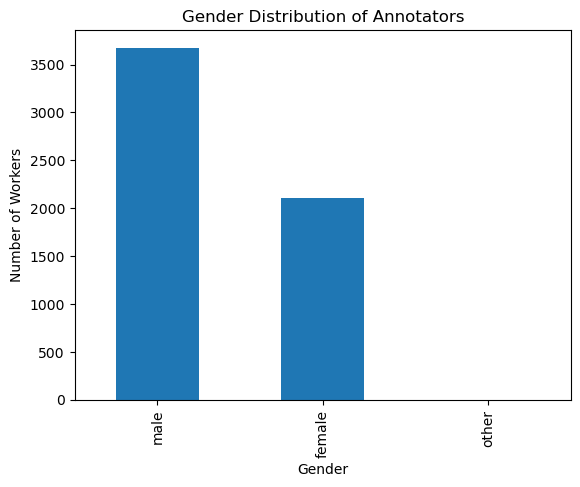

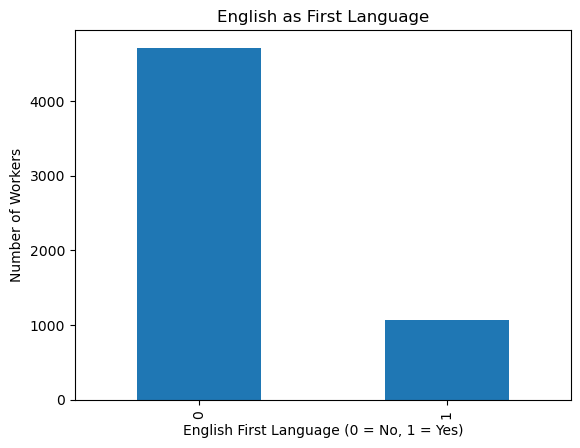

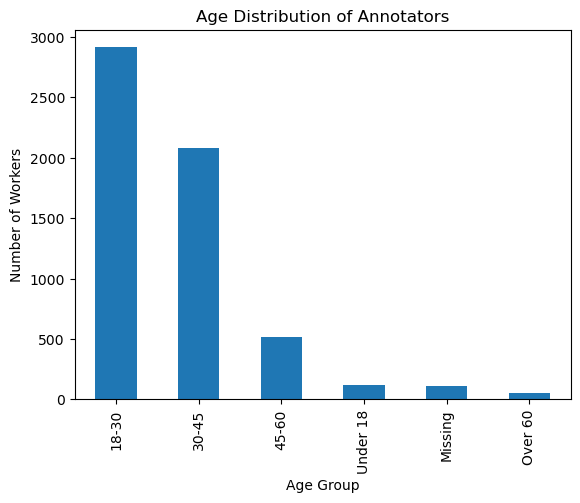

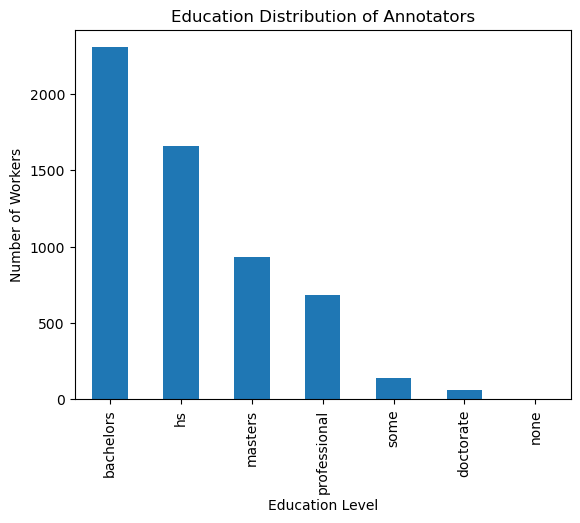

In [90]:
# Q1: Gender
gender_counts.plot(kind="bar", title="Gender Distribution of Annotators")
plt.xlabel("Gender")
plt.ylabel("Number of Workers")
plt.show()

# Q2: First language
language_counts.plot(kind="bar", title="English as First Language")
plt.xlabel("English First Language (0 = No, 1 = Yes)")
plt.ylabel("Number of Workers")
plt.show()

# Q3: Age group
age_counts = annotators_df["age_group"].value_counts(dropna=False)
age_counts.index = age_counts.index.map(
    lambda x: "Missing" if x == "" else x
)
age_counts.plot(kind="bar", title="Age Distribution of Annotators")
plt.xlabel("Age Group")
plt.ylabel("Number of Workers")
plt.show()

# Q4: Education
education_counts.plot(kind="bar", title="Education Distribution of Annotators")
plt.xlabel("Education Level")
plt.ylabel("Number of Workers")
plt.show()

### Q1: Gender

Most annotators were male. There were 3,676 male workers, 2,103 female workers, and only 2 workers categorized as other. This means the annotator pool was noticeably more male than female.

### Q2: First Language

Most annotators did not report English as their first language. There were 4,713 workers coded as 0 and 1,068 coded as 1 for English as a first language. This shows that workers who did not report English as their first language make up a large majority of the annotator pool.

### Q3: Age

The largest age group was 18–30 with 2,911 workers, followed by 30–45 with 2,078. Far fewer workers were over 45 or under 18. There were also 112 workers with no recorded age group, which is a limitation in the demographic data.

### Q4: Education

The most common education level was a bachelor's degree with 2,303 workers, followed by high school with 1,657 and a master's degree with 931. Very few workers reported having no formal education or a doctorate.

### 2.2 Questions 5-8

Each of the next four questions requires a different kinds of answer.

Questions 5 and 6 have a "correct" answer, but we'll still give you credit for the "incorrect" answer as long as you document your process well (in Markdown, in this notebook). These questions are intended to get you thinking about how even small errors in data processing can create bias in your data.

Question 6 requires you to re-run some (but not all) of the data processing steps you performed above. Do this by copying the code into NEW cells below this line, and make sure to document each step using Markdown cells or inline (#) comments. You will probably want to change the names of the variables too.

- **Q5.** Analyze all_annotators in Sheets or Jupyter: Do any of the fields in this dataset have missing data? If so, which fields, and what % of the rows contain missing values?
- **Q6.** Build a version of the all_annotators dataset *without removing duplicates*, then re-run the summary statistics from questions 1-4. How have these summary statistics changed?

Questions 7 and 8 don't have one "correct" answer. These questions are intended to get you thinking about how using this dataset to train a machine learning model might lead to bias in the way that model performs when used as intended. You will need to provide a written answer to each of these questions in 3-4 full sentences. Consider what you know about the workers themselves, the task they were given, and about the purpose of the Perspective API.

Question 7 requires you to do some research of your own (hint: use Google). Question 8 doesn't require any new analysis or research, just critical thinking.

- **Q7.** In general, how do the demographics of these workers compare to those of English-speaking internet users overall? Why would it matter if the worker demographics don't match the demographics of the intended end users of the Perspective API?

- **Q8.** Given what you now know about the Wikipedia Talk Corpus, what issues might arise if it was used to train a machine learning-driven "hostile speech detector" that could be used on any website or social media platform?


**POST YOUR ANSWERS TO QUESTIONS 5-8 HERE.**

Use both Markdown and code-formatted cells.

In [91]:
# Q5: Missing data

missing_counts = (annotators_df == "").sum()
missing_percent = ((annotators_df == "").sum() / len(annotators_df)) * 100

missing_summary = pd.DataFrame({
    "Missing values": missing_counts,
    "Percent missing": missing_percent
})

print(missing_summary)

                        Missing values  Percent missing
worker_id                            0         0.000000
gender                               0         0.000000
english_first_language               0         0.000000
age_group                          112         1.937381
education                            0         0.000000
dataset                              0         0.000000
unique_id                            0         0.000000


### Q5: Missing Data

The only field with missing data is `age_group`. There are 112 workers with no recorded age group, which is about 1.94% of the 5,781 rows. The other fields do not have any missing values.

In [92]:
# Q6: Build a version WITHOUT removing the duplicated attack/aggression file

all_annotators_with_dupes = (
    toxicity_annotators
    + attack_annotators
    + aggression_annotators
)

dupe_df = pd.DataFrame(all_annotators_with_dupes)

print("Total rows with duplicated file:", len(dupe_df))

print("\nGender")
print(dupe_df["gender"].value_counts(dropna=False))

print("\nEnglish first language")
print(dupe_df["english_first_language"].value_counts(dropna=False))

print("\nAge group")
print(dupe_df["age_group"].value_counts(dropna=False))

print("\nEducation")
print(dupe_df["education"].value_counts(dropna=False))

Total rows with duplicated file: 7971

Gender
gender
male      5025
female    2943
other        3
Name: count, dtype: int64

English first language
english_first_language
0    6501
1    1470
Name: count, dtype: int64

Age group
age_group
18-30       3960
30-45       2909
45-60        732
Under 18     153
             147
Over 60       70
Name: count, dtype: int64

Education
education
bachelors       3165
hs              2288
masters         1316
professional     927
some             189
doctorate         81
none               5
Name: count, dtype: int64


### Q6: Effect of Duplicate Data

When I included the duplicated attack/aggression file, the dataset increased from 5,781 to 7,971 rows. The counts increased across all demographic categories, but the proportions also changed slightly. For example, male workers changed from about 63.6% of the cleaned dataset to 63.0% of the duplicated dataset, while female workers increased from about 36.4% to 36.9%. This shows that duplicate data can skew the demographic distribution and lead to slightly different conclusions about who is represented in the dataset.

### Q7

The worker demographics do not fully match internet users overall. Our annotator pool was about 64% male and was heavily concentrated in the 18–45 age range, while current U.S. internet use is much more balanced by gender and is common across older age groups too. Pew reports that 96% of men and 97% of women use the internet, and 89% of adults age 65 and older are internet users. If the annotators do not represent the people who will actually use or be affected by the Perspective API, their judgments about toxicity may reflect a narrower set of experiences and norms.
Source: Pew Research Center, Internet/Broadband Fact Sheet.

### Q8

The Wikipedia Talk Corpus comes from one specific online community, so the language and behavior in it may not represent how people communicate on other websites. Platforms like TikTok, Reddit, or Instagram may use different slang, humor, tone, and social norms. The annotator demographics are also uneven, which could influence which comments were labeled toxic in the first place. A general-purpose hostile speech detector trained on this dataset could therefore misclassify language from groups or online communities that are not well represented in the training data.

## Part 3: Digging deeper

### 3.1 Questions 9-16

Below is a list of additional questions that you should be able to answer, based on what you've done today. 

***You may answer EITHER the "code" questions (Q9-Q12) OR the "no code" questions (Q13-Q16).***

If you don't feel very comfortable with Python yet, choose the "no code" questions.

- ***For the "code" questions*** you will need to load ``toxicity_annotations.tsv`` into Python and join that dataset with ``all_annotators`` on ``worker_id``.
- ***For the "no code" questions*** you will need to load the file ``toxicity_labelled_comments_3k_sample.csv`` into Google Sheets. This file contains the text of 3000 comments that were annotated for toxicity, as well as the toxicity score that each worker gave to these comments. The file is a random sample taken from the ~1.5 million comments contained in ``toxicity_annotated_comments.tsv``

*Note:* answering question 13-16 below ***will require reading some comments that contain offensive speech!*** If you do not want to be exposed to offensive speech, either answer the "code" questions instead, or reach out to your Instructor or TA and ask for an alternate activity.

#### Code questions
- **Q9.** What % of *workers* who labelled the toxicity dataset do we have demographic data for?
- **Q10.** What % of the *comments* in the toxicity dataset were labelled by male vs. female-identified workers?
- **Q11.** What % of the *comments* in the toxicity dataset were labelled by people for whom English is NOT their first language?
- **Q12.** Based on your findings from questions 9-11, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs? 

#### No-code questions

Before you answer the questions below, read through at least 20 comments from ``toxicity_labelled_comments_3k_sample.csv`` that were labelled "toxic" (-1 or -2), 20 that were labelled "non-toxic" (1 or 2), and 20 that are labelled "neutral" (0). Note in your spreadsheet whether you agree or disagree with the labeller's judgement. 


- **Q13.** Pick 2-3 examples of comments where you disagreed with the labeller about the toxicity of a comment. Why did you disagree? Why do you think that the labeller might have labelled these comments the way they did?
- **Q14.** Pick 2-3 examples of comments where you don't understand what the commenter was saying, and therefore had a hard time classifying as toxic or non-toxic. What additional context or information would you need in order to be confident in your judgement about the toxicity of this comment?
- **Q15.** Read through the [instructions and labelling options](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png) given to the crowdworkers. How could the way these instructions were written have made it difficult for crowdworkers to accurately label comments as toxic or non-toxic? If you were going to run a labelling campaign like this one yourself, how would you change these instructions or labelling options to help the crowdworkers make more accurate or consistent judgements about toxicity?
- **Q16.** Based on your findings from questions 13-15, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs as a general-purpose hostile speech detector? 

**POST YOUR ANSWERS TO QUESTIONS 9-16 HERE.**

Use both Markdown and code-formatted cells.

In [95]:
# Q9-Q11

# Demographic data for toxicity workers only
toxicity_demo_df = annotators_df[
    annotators_df["dataset"] == "toxicity"
].copy()

# Q9: Percent of workers who labelled toxicity comments
# for whom we have demographic data
annotation_worker_ids = set(toxicity_annotations_df["worker_id"])
demo_worker_ids = set(toxicity_demo_df["worker_id"])

workers_with_demo = annotation_worker_ids.intersection(demo_worker_ids)

q9_percent = (
    len(workers_with_demo) / len(annotation_worker_ids)
) * 100

print("Q9")
print("Total toxicity workers:", len(annotation_worker_ids))
print("Workers with demographics:", len(workers_with_demo))
print("Percent with demographics:", round(q9_percent, 2), "%")


# Join each annotation with the worker's demographics
merged = toxicity_annotations_df.merge(
    toxicity_demo_df,
    on="worker_id",
    how="left"
)


# Q10: Gender of workers who made the annotations
gender_for_annotations = merged["gender"].fillna("unknown")
gender_counts = gender_for_annotations.value_counts()
gender_percent = (
    gender_counts / len(merged) * 100
)

print("Q10")
print(gender_counts)
print(gender_percent.round(2))


# Q11: English first language
language_labels = merged["english_first_language"].map({
    "0": "English is not first language",
    "1": "English is first language"
}).fillna("unknown")
language_counts = language_labels.value_counts()
language_percent = (
    language_counts / len(merged) * 100
)

print("\nQ11")
print(language_counts)
print(language_percent.round(2))

Q9
Total toxicity workers: 4301
Workers with demographics: 3591
Percent with demographics: 83.49 %
Q10
gender
male       889251
female     457346
unknown    251334
other         358
Name: count, dtype: int64
gender
male       55.64
female     28.61
unknown    15.73
other       0.02
Name: count, dtype: float64

Q11
english_first_language
English is not first language    1113162
unknown                           251334
English is first language         233793
Name: count, dtype: int64
english_first_language
English is not first language    69.65
unknown                          15.73
English is first language        14.63
Name: count, dtype: float64


### Q9

There were 4,301 workers who labeled the toxicity dataset, and demographic data was available for 3,591 of them. That means we have demographic information for about 83.49% of the toxicity workers.

### Q10

About 55.64% of toxicity annotations were made by male workers, 28.61% by female workers, and 0.02% by workers categorized as other. Gender information was unknown for 15.73% of annotations. This means male workers still contributed substantially more labels than female workers, but a noticeable portion of the annotations cannot be linked to known gender data.

### Q11

About 69.65% of toxicity annotations were made by workers whose first language was not English, while 14.63% were made by workers whose first language was English. First-language information was unknown for 15.73% of annotations. This means most of the toxicity labels came from workers who reported that English was not their first language.

### Q12

These results suggest that the dataset may reflect some groups' judgments more strongly than others. Male workers contributed over half of the annotations, and most annotations came from workers whose first language was not English, while about 15.73% of annotations could not be connected to demographic information at all. Since judgments about toxicity can depend on language, slang, tone, and cultural context, these differences could affect how comments were labeled. A model trained on these labels could learn the same patterns and may perform differently for groups or types of language that were less represented.

#### 3.2 Challenge questions (optional)

The questions below are optional; you don't need to answer them to receive full credit for this assignment.

If you'd like to explore additional analyses of this dataset, here are a few questions to get you started!

- ***Challenge #1.*** Are female-identified workers more likely to label a comment as "toxic" than male identified workers? 
- ***Challenge #2.*** Are workers with a higher level of education more consistent in their "toxicity" labelling--in other words, do they tend to agree with other labellers more often? (remember that, according to the documentation, every comment was labelled by at least 10 crowdworkers). 
- ***Challenge #3.*** What are the words most frequently associated with toxic comments? (perhaps focus on comments where most or all of the workers agree are toxic)
- ***Challenge #4.*** What are the most polarizing comments--comments that some workers consider toxic, and others consider non-toxic? What about these comments made them so polarizing, or hard to classify?
- ***Challenge #5.*** Answer some or all of the homework questions above for one the other datasets ("attack" and "aggressive"). How are the potential sources of bias for these datasets the same, or different, than for the toxicity dataset? Would you "trust" a machine learning model based on these datasets more or less than one trained on the "toxicity" dataset? Why?

*OPTIONAL: POST YOUR ANSWERS TO THE CHALLENGE QUESTIONS HERE.*

Use both Markdown and code-formatted cells.

In [94]:
# Challenge 2: Agreement by education level

# Make sure toxicity is numeric
merged["toxicity"] = pd.to_numeric(
    merged["toxicity"],
    errors="coerce"
)

# Average toxicity judgment for each comment
comment_average = (
    merged.groupby("rev_id")["toxicity"]
    .mean()
    .rename("comment_avg")
)

challenge2 = merged.merge(
    comment_average,
    on="rev_id",
    how="left"
)

# Difference between each worker's judgment
# and the average judgment for that comment
challenge2["difference_from_group"] = abs(
    challenge2["toxicity"] - challenge2["comment_avg"]
)

# Lower value = more agreement with other annotators
education_agreement = (
    challenge2.groupby("education")["difference_from_group"]
    .mean()
    .sort_values()
)

print(education_agreement)

education
doctorate       0.109790
some            0.112038
professional    0.114259
hs              0.116769
masters         0.117844
none            0.120041
bachelors       0.122093
Name: difference_from_group, dtype: float64


### Challenge 2

I measured consistency by comparing each worker's toxicity label with the average label given to the same comment. A lower difference means that workers in that education group tended to agree more closely with the other annotators. Workers with doctorates had the lowest average difference, while workers with bachelor's degrees had the highest. However, the results do not show a clear pattern where more education consistently leads to more agreement, so education level alone does not appear to strongly predict consistency in toxicity labeling.

### AI Acknowledgment

I used ChatGPT throughout this assignment to help me understand the instructions, troubleshoot Python errors, and check my analysis.

Some of the prompts I used included:

- “Help me understand why `worker_id` is duplicated across these datasets.”
- “Why am I getting `NameError: name 'toxicity_annotators' is not defined`?”
- “Why is `random.sample()` giving me a TypeError when I use a set?”
- “Help me write Python code for Questions 1–4 to calculate the gender, first-language, age, and education distributions.”
- “How do I check which fields have missing data and what percent of rows are missing?”
- “Help me build a version of the annotator dataset without removing the duplicated attack/aggression file so I can compare the results.”
- “Help me load `toxicity_annotations.tsv` and join it with the annotator demographic data on `worker_id`.”
- “Help me calculate Questions 9–11, including the percent of toxicity workers with demographic data and the demographic breakdown of annotations.”
- “Why am I getting `TypeError: Could not convert string ... to numeric` when calculating the average toxicity label for Challenge 2?”
- “Check my entire assignment thoroughly to make sure it is ready for submission.”

I ran the code myself in Jupyter, checked the outputs against the assignment instructions, and revised my analysis when the results showed issues such as duplicate data, missing demographic information, or annotations that could not be matched to worker demographics. I used ChatGPT as a debugging and interpretation aid, but I reviewed the final code, results, and written responses before submitting.